# 03 — Labels, features and triage / 標籤、特徵與五道關卡

**EN** Labels start at the next open like the backtest fills. Each of the 24 candidate features goes through five gates (placebo, HAC IC, shape, feasibility, BH/Holm); failures are listed, not hidden.

*Needs `data/` and `artifacts/` from the shared Drive folder (see README).*

**中文** 標籤與回測一樣從隔日開盤起算。24 個候選特徵都經過五道關卡（placebo、HAC IC、形狀、可行性、BH/Holm），失敗者照列。

*需要先從 README 的 Drive 連結下載 `data/` 與 `artifacts/`。*

In [1]:
# Locate the repository root and load the library (works from the root or notebooks/)
# 找到 repo 根目錄並載入函式庫（從根目錄或 notebooks/ 執行皆可）
import os, sys, json, subprocess
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "setup.yaml").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import yaml
from IPython.display import Image, Markdown, display
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 4)


def show(fig, width=820):
    """Show a committed figure / 顯示已產出的圖"""
    display(Image(filename=str(ROOT / "reports" / "figures" / fig), width=width))


def sh(cmd):
    """Run a repository command from the root and print its output / 在根目錄執行指令並印出結果"""
    r = subprocess.run(cmd, shell=True, cwd=ROOT, capture_output=True, text=True, encoding="utf-8")
    print(r.stdout[-4000:], r.stderr[-2000:])
    return r.returncode

In [2]:
# Triage table: one row per candidate, with the gate results / 每個候選特徵一列及各關卡結果
tri = pd.read_csv("reports/triage_table.csv")
cols = ["feature", "role", "expected_sign", "ic_mean", "ic_ci_low", "ic_ci_high", "placebo_ratio_lag21",
        "g1_pass", "g3_pass", "g4_pass"] + [c for c in ("q_bh", "decision", "reason") if c in tri]
display(tri[cols])
print(tri["decision"].value_counts() if "decision" in tri else "")

,feature,role,expected_sign,ic_mean,ic_ci_low,ic_ci_high,placebo_ratio_lag21,g1_pass,g3_pass,g4_pass,q_bh,decision,reason
0,fund_1d,signal,-,-0.0411,-0.0560,-0.0261,0.8327,False,True,True,2.0851e-07,REVISE,timing placebo keeps 83% of IC at lag 21 (slow...
1,fund_7d,signal,-,-0.0353,-0.0529,-0.0176,1.0758,False,True,True,2.1845e-04,REVISE,timing placebo keeps 108% of IC at lag 21 (slo...
2,fund_30d,signal,-,-0.0280,-0.0467,-0.0093,0.7875,False,True,True,6.2487e-03,REVISE,timing placebo keeps 79% of IC at lag 21 (slow...
3,fund_z_90d,signal,-,0.0099,-0.0048,0.0245,0.0825,True,False,True,2.2612e-01,STOP,no detectable association (BH q >= 0.05 or CI ...
4,fund_chg_7d,signal,-,0.0005,-0.0121,0.0131,26.0766,True,False,False,9.3974e-01,STOP,no detectable association (BH q >= 0.05 or CI ...
5,oi_chg_1d,signal,-,0.0062,-0.0002,0.0126,0.5139,True,False,False,7.8968e-02,STOP,no detectable association (BH q >= 0.05 or CI ...
6,oi_chg_7d,signal,-,-0.0097,-0.0205,0.0010,0.1797,True,False,False,9.8652e-02,STOP,no detectable association (BH q >= 0.05 or CI ...
7,oi_to_adv,state,-,0.0873,0.0676,0.1070,0.7437,False,True,False,0.0000e+00,REVISE,significant with the opposite sign: mechanism ...
8,lsr_div,signal,+,-0.0221,-0.0395,-0.0047,0.4440,True,True,True,2.0016e-02,REVISE,significant with the opposite sign: mechanism ...
9,lsr_div_chg_7d,signal,+,-0.0174,-0.0307,-0.0040,0.4437,True,False,False,1.8119e-02,REVISE,significant with the opposite sign: mechanism ...


decision
REVISE     11
STOP        6
CONTROL     3
Name: count, dtype: int64


In [3]:
# Recompute one feature's daily IC live and compare with the table / 即時重算一個特徵的 IC 並與表格比對
from crowding.sample import load_sample
from crowding.triage import xs_ic
from crowding.stats import newey_west
dev = load_sample("dev", horizon=7)
ic = xs_ic(dev, "fund_1d", "y_total_7d")
mean, se = newey_west(ic.dropna().to_numpy(), 7)
print(f"fund_1d live IC {mean:+.4f} vs table {tri.set_index('feature').loc['fund_1d', 'ic_mean']:+.4f}")

fund_1d live IC -0.0411 vs table -0.0411


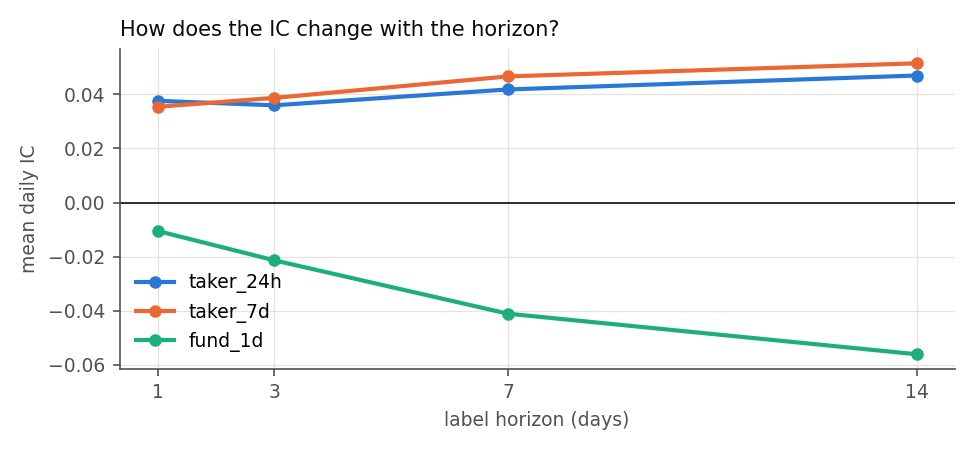

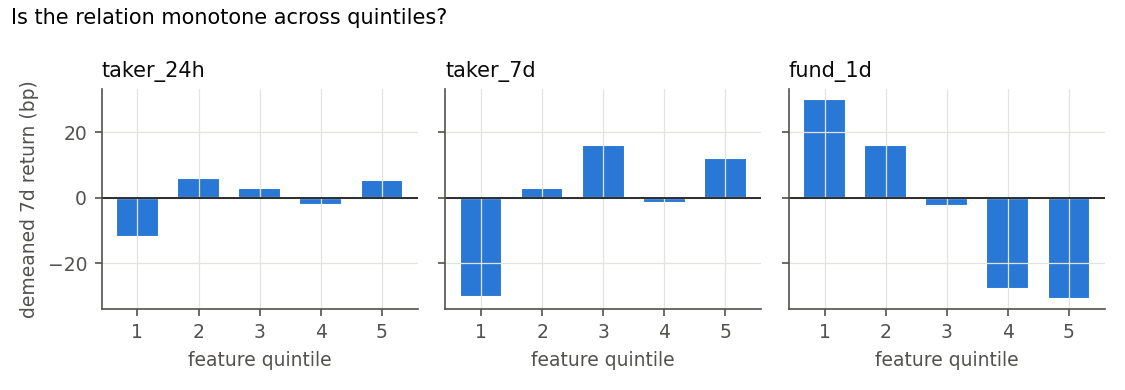

In [4]:
# IC decay over horizons and quintile shape / 不同期限的 IC 衰減與五分位形狀
show("triage_ic_decay.png"); show("triage_quintiles.png")

In [5]:
# Market-state features (they condition the rule, not rank names) / 市場狀態特徵
display(pd.read_csv("reports/triage_market_state.csv")[["feature", "ic_diff", "ic_diff_ci_low", "ic_diff_ci_high", "q_bh", "decision"]])

,feature,ic_diff,ic_diff_ci_low,ic_diff_ci_high,q_bh,decision
0,mkt_fund_7d,0.0622,0.0165,0.1080,0.0306,PROCEED
1,xs_fund_disp,-0.0431,-0.0920,0.0058,0.1686,STOP
2,btc_ret_7d,0.0149,-0.0246,0.0545,0.6114,STOP
3,btc_rvol_20d,0.0005,-0.0643,0.0653,0.9871,STOP


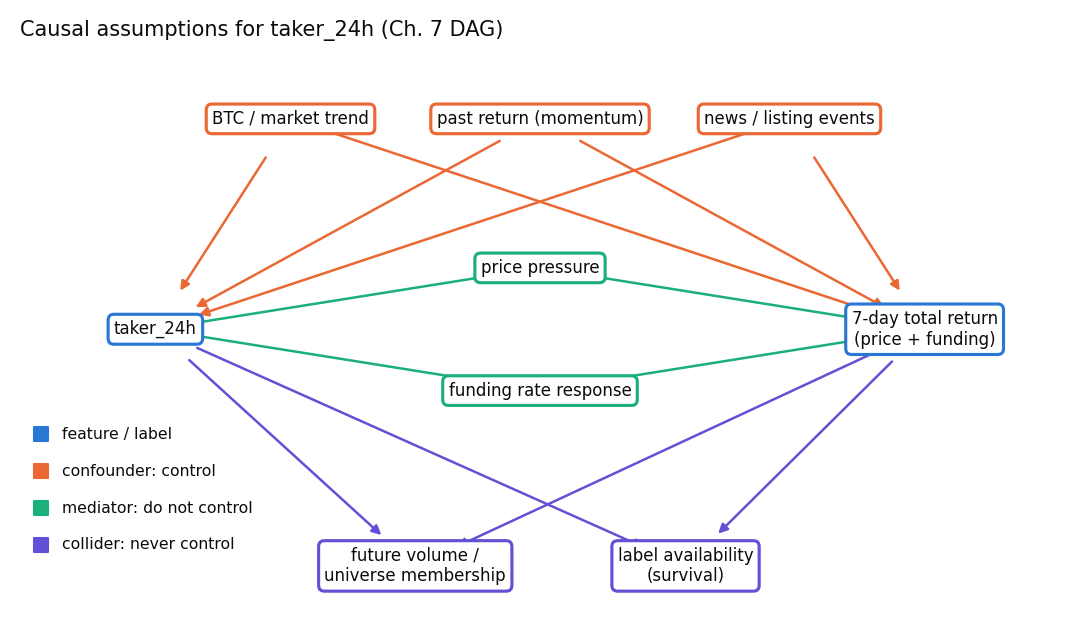

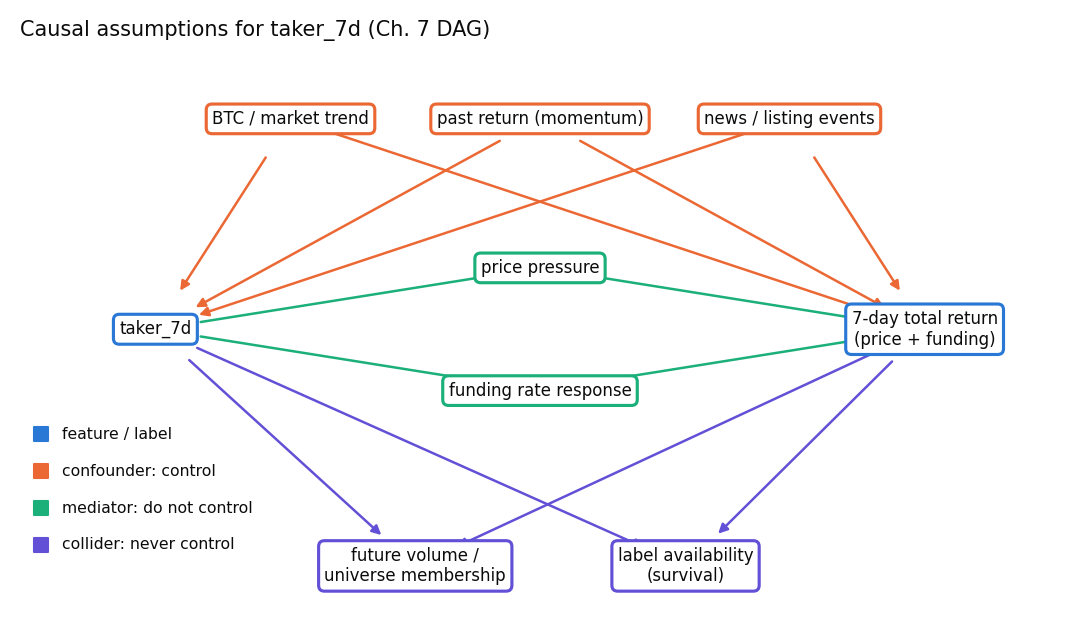

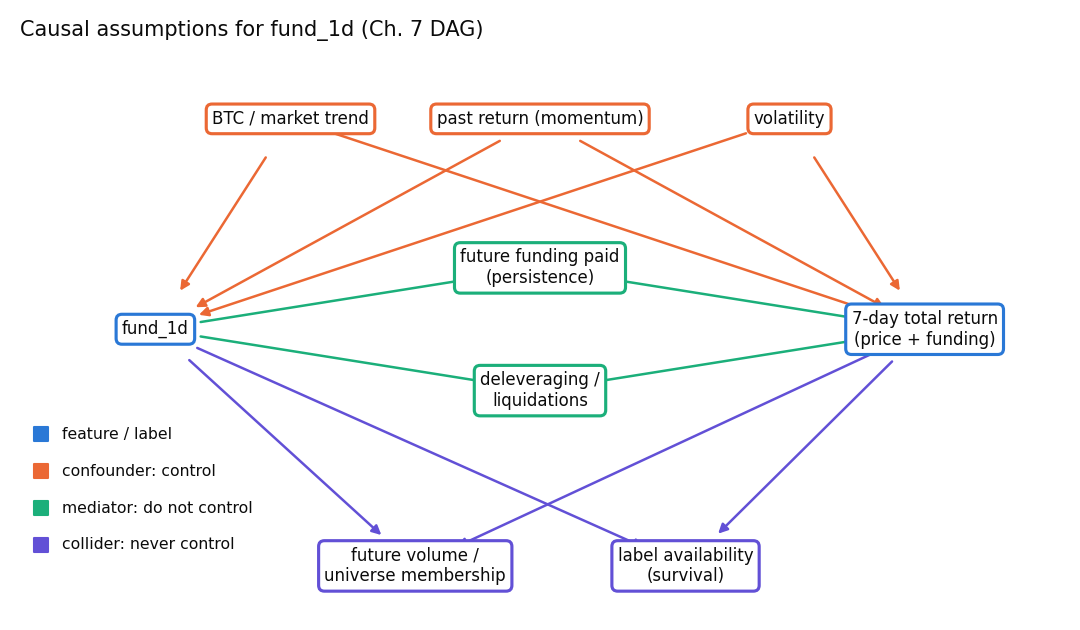

In [6]:
# DAGs of the top three features / 前三名特徵的 DAG
for f in ("triage_dag_taker_24h.png", "triage_dag_taker_7d.png", "triage_dag_fund_1d.png"):
    show(f, 600)